# Step 2: Tracking Cells Through a Movie

Once a movie is registered (step 1) and each frame has been segmented into a
labeled instance mask, the remaining problem is: **which blob in frame `t+1`
is the same physical cell as which blob in frame `t`?** Plain per-frame
segmentation has no memory of identity between frames, and yeast cells
divide and mate (fuse), so the number of objects changes over time too.

`cellmate.tracking.Tracker` (an IoU tracker) solves this by matching masks
between consecutive frames using intersection-over-union, plus two special
cases:

* **division** -- one tracked object splits into two,
* **fusion** -- two tracked objects merge into one (the event of primary
  interest for a *mating* assay: the moment two cells fuse).

The result is (a) a re-labeled movie where every frame's instance IDs are
now temporally consistent, and (b) a small lineage graph recording every
division/fusion relationship.

A command-line equivalent (`02_tracking_movie.py`) is included in this same
folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.io import imread, imsave

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cellmate").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Tracker lives in a private module and isn't re-exported from
# `cellmate.tracking.__init__`, so it's imported directly like this.
from cellmate.tracking._iou_tracker import Tracker
from cellmate.visualize import label2rgb, draw_graph_by_layer
from cellmate.utils import dump_to_pkl

print("cellmate loaded from:", REPO_ROOT / "cellmate")

cellmate loaded from: /home/wlli/project/CellMate/cellmate


## 1. Load a segmented movie

The bundled example here has already been registered and segmented: it is a
`[Time, Channel, Height, Width]` stack where the **last channel** is an
instance-segmentation mask. Each label encodes both a semantic class and an
instance id as `label = semantic_class * 1000 + instance_id`
(see `cellmate.configs.DIVISION`) -- e.g. label `1003` is instance 3 of
semantic class 1.

In [2]:
input_path = REPO_ROOT / "demo" / "YAV2104xYAV2105_20220826_exp011_05_R3D_rigid_003002.tif"
image = imread(str(input_path))
masks = image[:, -1]
print("mask movie shape (T, H, W):", masks.shape, masks.dtype)
print("labels in frame 0:", np.unique(masks[0])[1:])

mask movie shape (T, H, W): (145, 250, 250) uint16
labels in frame 0: [1001 1002 1003 1004]


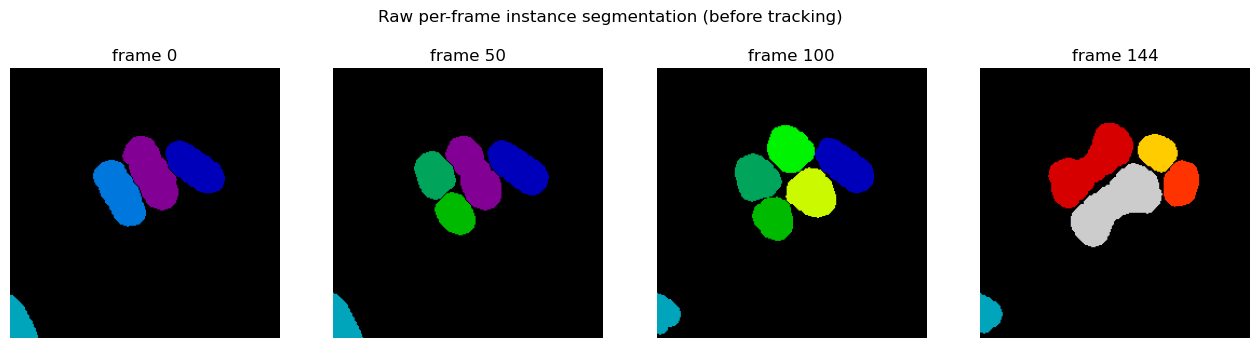

In [3]:
# label2rgb assigns colors by each unique label's *rank* among the unique
# values it is given -- call it once on the whole [T, H, W] stack (rather
# than once per frame) so a given label gets the same color everywhere.
raw_rgb = label2rgb(masks)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, t in zip(axes, [0, 50, 100, 144]):
    ax.imshow(raw_rgb[t])
    ax.set_title(f"frame {t}")
    ax.axis("off")
plt.suptitle("Raw per-frame instance segmentation (before tracking)")
plt.show()

This is *per-frame* segmentation: nothing here formally guarantees that
label `1001` in frame 0 and label `1001` in frame 100 are the same physical
cell -- it's just a per-frame instance id. In particular, per-frame
segmentation alone can never tell you that two cells *fused* or that one
*divided*, since that requires comparing across frames. That's exactly the
gap tracking fills.

## 2. Run the tracker

Key parameters:

| parameter | meaning |
|---|---|
| `threshold` | minimum mask IoU between frames to call it the same object |
| `min_hist` | drop tracks shorter than this many frames from the output (filters out one-off segmentation noise) |
| `max_miss` | how many consecutive frames an object may go undetected before its track is closed |

The tracker prints its progress frame-by-frame, plus a line every time it
detects a division or a fusion -- keep an eye out for `fusion:` events
below, since those are candidate mating events.

In [4]:
tracker = Tracker(masks, threshold=0.25, min_hist=1, max_miss=10)
_ = tracker()

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
division:  1003  ->  1005 1006
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
division:  1001  ->  1007 1008
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
fusion:  1006 1008  ->  3009
106
107
108
109
110
111
112
113
114
fusion:  1005 1007  ->  2010
115
116
117
division:  2010  ->  1005 1007
118
fusion:  1005 1007  ->  2010
119
120
121
122
123
124
125
126
127
128
129
division:  1002  ->  1011 1012
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144


## 3. Inspect the results

In [5]:
tracked_image = tracker.to_image()
print("tracked movie shape:", tracked_image.shape)
print("total tracked objects (including short-lived ones):", len(tracker.all_trackers()))

divisions = sum(1 for *_, w in tracker.network.edges(data="weight") if w == 1) // 2
fusions = sum(1 for *_, w in tracker.network.edges(data="weight") if w == 2) // 2
print(f"divisions detected: {divisions}, fusions (matings) detected: {fusions}")

tracked movie shape: (145, 250, 250)
total tracked objects (including short-lived ones): 15
divisions detected: 4, fusions (matings) detected: 3


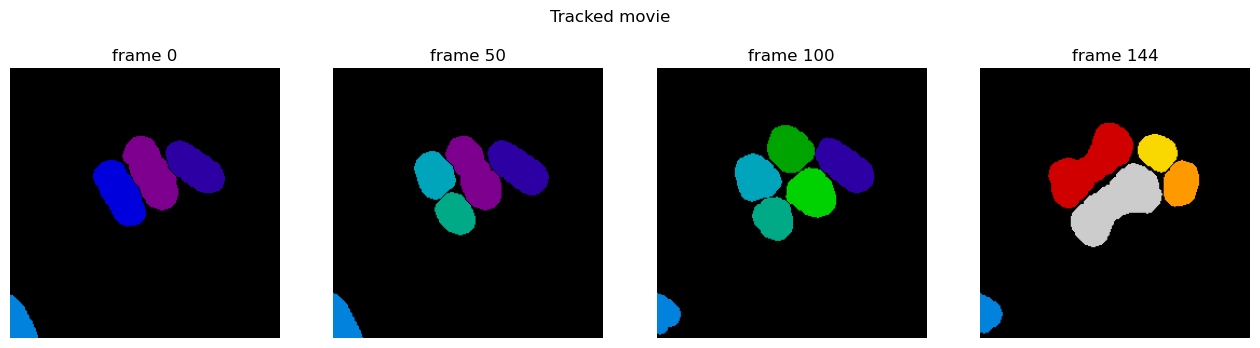

In [6]:
tracked_rgb = label2rgb(tracked_image)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, t in zip(axes, [0, 50, 100, 144]):
    ax.imshow(tracked_rgb[t])
    ax.set_title(f"frame {t}")
    ax.axis("off")
plt.suptitle("Tracked movie")
plt.show()

The real proof that identity is now well-defined isn't the picture -- it's
that every tracked object carries an explicit, queryable lifespan. Each
entry in `tracker.all_trackers()` is a `TrackedBox` recording every frame it
was seen in (`.frame`) and its label at that frame (`.label`), which we can
turn into a lifespan table:

In [7]:
lifespans = pd.DataFrame([
    {"id": trk.id, "category": trk.category(),
     "start_frame": trk.frame[0], "end_frame": trk.frame[-1],
     "n_frames": len(trk.frame)}
    for trk in tracker.all_trackers()
]).sort_values("start_frame").reset_index(drop=True)
lifespans

,id,category,start_frame,end_frame,n_frames
0,3,1,0,24,25
1,1,1,0,58,59
2,2,1,0,128,129
3,4,1,0,144,145
4,6,1,25,104,80
5,5,1,25,113,89
6,8,1,59,104,46
7,7,1,59,113,55
8,9,3,105,144,40
9,10,2,114,116,3


Cross-reference this table with the `division:`/`fusion:` lines printed
above: e.g. object `3` (frames 0-24) divides into objects `5` and `6` right
where the log says `division: 1003 -> 1005 1006`, and objects `6` and `8`
later fuse into object `9` (`category` `3`, a mating product) exactly where
the log says `fusion: 1006 1008 -> 3009`. None of that relationship is
recoverable from a single frame's raw mask alone.

## 4. Visualize the lineage graph

`tracker.network` is a small `networkx.DiGraph` (`cellmate.network.NetCell`)
recording every division (edge weight `1`) and fusion (edge weight `2`)
between tracked-object ids.

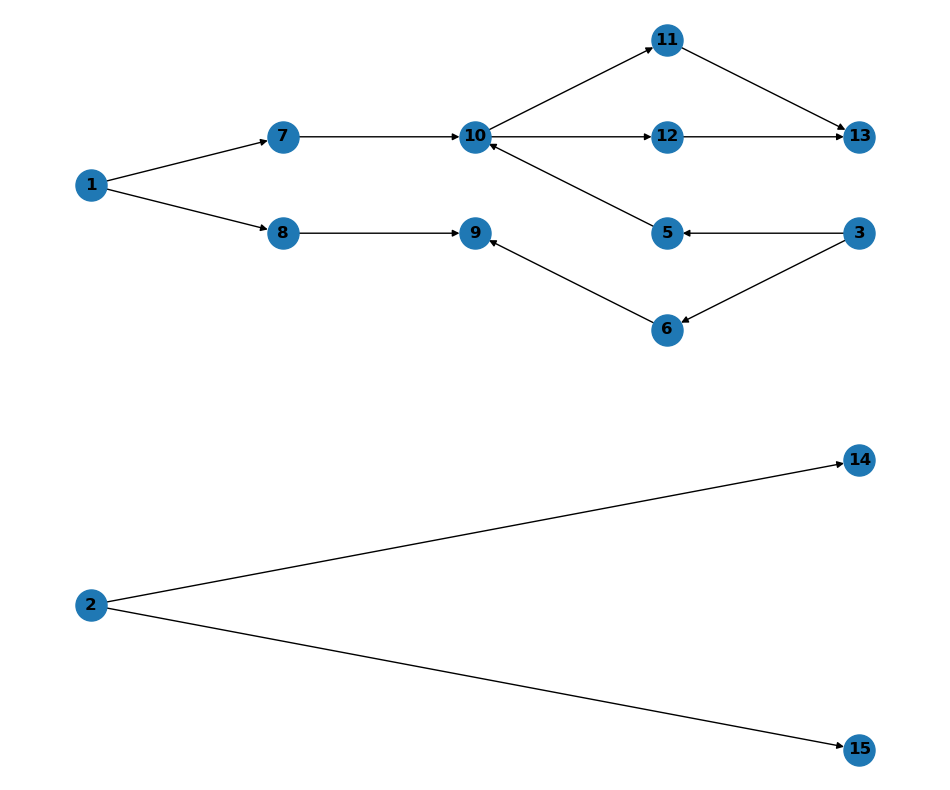

In [8]:
draw_graph_by_layer(tracker.network)
plt.show()

## 5. Save the results

* the re-labeled movie (`to_image()`), where `label = tracker_id +
  category * 1000`,
* the lineage graph, and
* each object's frame-by-frame history (`save_trackers()`) -- handy for
  later joining with per-frame measurements from step 3.

In [9]:
output_dir = REPO_ROOT / "demo" / "quickstart" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

imsave(str(output_dir / "02_tracked_movie_demo.tif"),
      tracked_image.astype(np.uint16), imagej=True, check_contrast=False)
dump_to_pkl(tracker.network, output_dir / "02_tracking_network_demo.pkl")
dump_to_pkl(tracker.save_trackers(), output_dir / "02_tracking_trackers_demo.pkl")
print("saved outputs to", output_dir)

saved outputs to /home/wlli/project/CellMate/demo/quickstart/outputs


## Parameter tuning tips

* Lower `threshold` if fast-moving/deforming cells lose their track between
  frames (more permissive matching); raise it if unrelated neighboring cells
  get incorrectly merged.
* Raise `max_miss` if segmentation sometimes drops a cell for a frame or two
  (e.g. out of focus) and you don't want that to end its track.
* Raise `min_hist` to discard short, likely-spurious tracks from the final
  output (they're still tracked internally, just filtered out of
  `to_image()`/`save_trackers()`).
* `is_allow_new_object=True` (constructor argument) lets brand-new objects
  appear mid-movie instead of only division/fusion producing new ids --
  useful if cells can drift into the field of view.

## Command-line equivalent

```bash
python 02_tracking_movie.py \
    --input ../YAV2104xYAV2105_20220826_exp011_05_R3D_rigid_003002.tif \
    --mask-channel -1 \
    --threshold 0.25 --min-hist 1 --max-miss 10
```

Run `python 02_tracking_movie.py --help` for the full list of options.